# Taller autonomo – Modelos predictivos y no supervisados
**Analitica de Datos II Universidad Icesi**  

**Estudiante:** 

Eva Sophia Larrahondo

John Esteban Polo

In [2]:
import warnings
warnings.filterwarnings("ignore") 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Semilla global
SEED = 42
np.random.seed(SEED)

In [3]:
df = pd.read_csv("clientes_domicilios_cali.csv")

* ¿Que clientes van a abandonar la app el proximo mes? Quieren ofrecerles un
beneficio antes de que se vayan. 

* ¿Cuanto va a gastar cada cliente el proximo mes? Quieren proyectar ingresos.

* segmentar a los clientes en perfiles


## Paso 1: Exploracion

In [4]:
print("el numero de filas y columnas del dataframe es ",df.shape)
df.info()
df.describe()


el numero de filas y columnas del dataframe es  (1500, 16)
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_cliente                   1500 non-null   str    
 1   edad                         1456 non-null   float64
 2   zona                         1500 non-null   str    
 3   antiguedad_meses             1500 non-null   int64  
 4   plan_premium                 1500 non-null   str    
 5   metodo_pago                  1500 non-null   str    
 6   pedidos_mes                  1500 non-null   int64  
 7   ticket_promedio              1500 non-null   int64  
 8   distancia_promedio_km        1459 non-null   float64
 9   tiempo_entrega_promedio_min  1500 non-null   int64  
 10  uso_cupones_pct              1500 non-null   float64
 11  quejas_6m                    1500 non-null   int64  
 12  calificacion_app            

,edad,antiguedad_meses,pedidos_mes,ticket_promedio,distancia_promedio_km,tiempo_entrega_promedio_min,uso_cupones_pct,quejas_6m,calificacion_app,dias_desde_ultimo_pedido,gasto_proximo_mes,abandono
count,1456.000000,1500.000000,1500.000000,1500.000000,1459.000000,1500.000000,1500.000000,1500.000000,1470.000000,1500.000000,1.500000e+03,1500.000000
mean,30.548764,20.561333,7.877333,47905.933333,4.393763,30.382667,33.433533,1.075333,3.975170,14.273333,3.982783e+05,0.278667
std,8.766562,14.736769,7.885159,34866.915923,3.476179,8.216563,24.170144,1.431674,0.757842,17.873246,3.399163e+05,0.448493
min,18.000000,1.000000,0.000000,15700.000000,0.500000,5.000000,0.000000,0.000000,1.000000,0.000000,0.000000e+00,0.000000
25%,24.000000,6.000000,3.000000,33500.000000,2.800000,25.000000,13.475000,0.000000,3.600000,3.000000,1.699500e+05,0.000000
50%,29.000000,20.000000,6.000000,41750.000000,4.100000,30.000000,27.400000,1.000000,4.100000,8.000000,2.714000e+05,0.000000
75%,35.000000,32.000000,11.000000,55625.000000,5.400000,36.000000,53.225000,2.000000,4.500000,19.000000,4.910000e+05,1.000000
max,69.000000,72.000000,105.000000,574000.000000,59.600000,61.000000,100.000000,8.000000,5.000000,120.000000,1.910100e+06,1.000000


**Lectura:** el dataset tiene 1.500 clientes y 16 columnas. Solo `edad`, `distancia_promedio_km` y `calificacion_app` tienen valores faltantes. El `describe()` ya adelanta que hay variables con colas muy largas

datos faltantes por cada columna

In [5]:
df.isna().sum() 

id_cliente                      0
edad                           44
zona                            0
antiguedad_meses                0
plan_premium                    0
metodo_pago                     0
pedidos_mes                     0
ticket_promedio                 0
distancia_promedio_km          41
tiempo_entrega_promedio_min     0
uso_cupones_pct                 0
quejas_6m                       0
calificacion_app               30
dias_desde_ultimo_pedido        0
gasto_proximo_mes               0
abandono                        0
dtype: int64

faltan 44 edades (2,9 %), 41 distancias (2,7 %) y 30 calificaciones (2,0 %). Son porcentajes bajos

abandono
0    1082
1     418
Name: count, dtype: int64
abandono
0    72.1
1    27.9
Name: proportion, dtype: float64


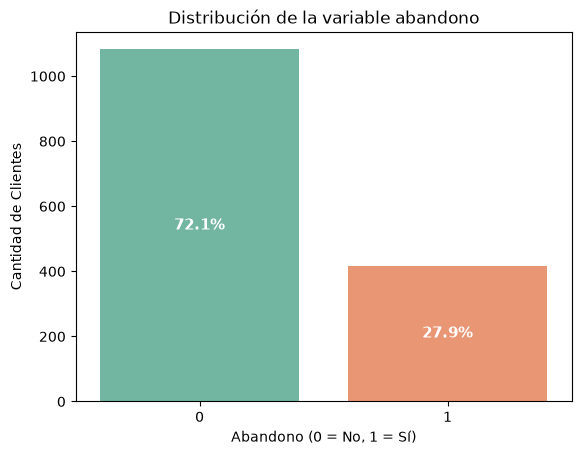

In [6]:
conteoabandono = df['abandono'].value_counts()
percentajeabandono = df['abandono'].value_counts(normalize=True) * 100
print(conteoabandono)
print(percentajeabandono.round(1))

#grafica
ax = sns.countplot(data=df, x='abandono', palette='Set2')
plt.title('Distribución de la variable abandono')
plt.xlabel('Abandono (0 = No, 1 = Sí)')
plt.ylabel('Cantidad de Clientes')
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{(height / total) * 100:.1f}%'
    ax.annotate(percentage, 
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', 
                fontsize=11, color='white', weight='bold')

plt.show()


se calculo la frecuencia absoluta de la variable abandono, con la cual se calculo el pocertanje de clientes que abandonan la app, al realizar la grafica se encuentra que cerca de un 72% de los clientes que se quedan en esta y cerca del 28% la abandonan

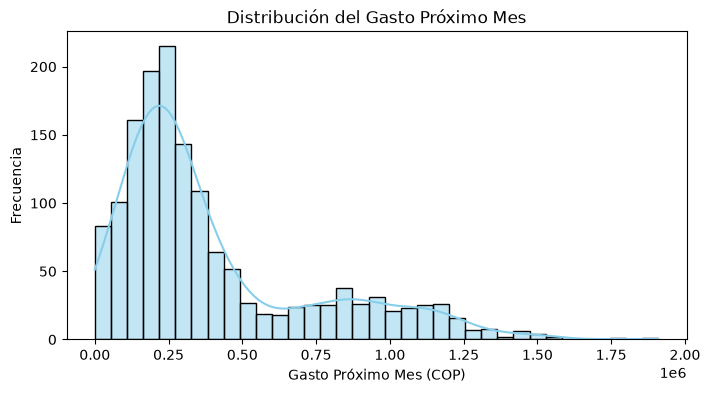

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='gasto_proximo_mes', kde=True, color='skyblue')
plt.title('Distribución del Gasto Próximo Mes')
plt.xlabel('Gasto Próximo Mes (COP)')
plt.ylabel('Frecuencia')
plt.show()

mediante el analisis grafico, hallamos que tiene una distribucion asimetrica positiva, en donde la mayoria de los clientes gasta poco, y unos pocos generan un gran volumen de gasto.

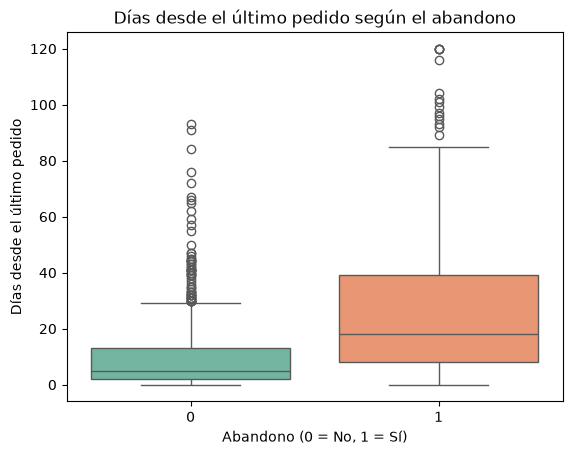

In [8]:
sns.boxplot(data=df, x='abandono', y='dias_desde_ultimo_pedido', palette='Set2')
plt.title('Días desde el último pedido según el abandono')
plt.xlabel('Abandono (0 = No, 1 = Sí)')
plt.ylabel('Días desde el último pedido')
plt.show()

los clientes que abandonan pasan en promedio mas dias sin realiza un pedido que los clientes activos en la app, se puede apreciar una gran cantidad de datos atipicos en ambos grupos, los clientes que aun estan activos en la app pero llevan entre 80 y 100 dias sin realiza un pedidod son clientes ocasionales que solo hacen uso de los servicios de la app para fechas especiales

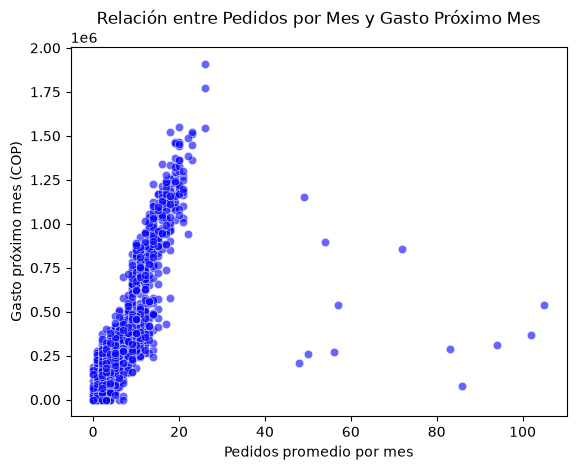

In [9]:
sns.scatterplot(data=df, x='pedidos_mes', y='gasto_proximo_mes', alpha=0.6, color='b')
plt.title('Relación entre Pedidos por Mes y Gasto Próximo Mes')
plt.xlabel('Pedidos promedio por mes')
plt.ylabel('Gasto próximo mes (COP)')
plt.show()

se nota como la mayoria de los datos se acumulan a la izquierda, alcanzando un pico en 20 pedido en donde los clientes en el proximo mes van a gastar mas, esto indica una tendencia lineal, hay varios datos atipicos que representan clientes con un gran volumen de pedidos pero que gastan poco el mes siguiente

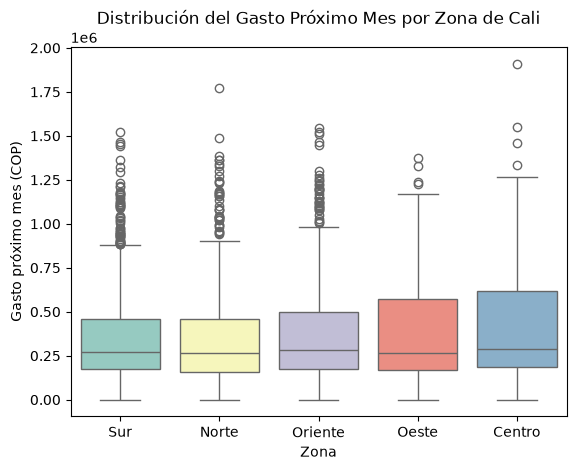

In [10]:
sns.boxplot(data=df, x='zona', y='gasto_proximo_mes', palette='Set3')
plt.title('Distribución del Gasto Próximo Mes por Zona de Cali')
plt.xlabel('Zona')
plt.ylabel('Gasto próximo mes (COP)')
plt.show()

aunque la cajas y los bigotes de la zona centro y oeste son mas grandes que en el resto de zonas, esto indica una mayor variabilidad en estas dos zonas

In [ ]:
#¿hay valores imposibles o muy raros? Revisamos los extremos de las variables numéricas
cols_num = ['edad','antiguedad_meses','pedidos_mes','ticket_promedio','distancia_promedio_km',
            'tiempo_entrega_promedio_min','uso_cupones_pct','quejas_6m','calificacion_app',
            'dias_desde_ultimo_pedido','gasto_proximo_mes']
display(df[cols_num].describe(percentiles=[.5, .99]).T[['min','50%','99%','max']])

# Casos concretos que llaman la atención
print("\nMás de 40 pedidos al mes:", (df['pedidos_mes'] > 40).sum())
print("Ticket promedio > 300.000 COP:", (df['ticket_promedio'] > 300000).sum())
print("Distancia > 30 km:", (df['distancia_promedio_km'] > 30).sum())
print("Entrega en <= 7 min con distancia > 30 km:", ((df['tiempo_entrega_promedio_min'] <= 7) & (df['distancia_promedio_km'] > 30)).sum())
print("Gasto del próximo mes = 0:", (df['gasto_proximo_mes'] == 0).sum())

,min,50%,99%,max
edad,18.0,29.0,56.00,69.0
antiguedad_meses,1.0,20.0,54.00,72.0
pedidos_mes,0.0,6.0,23.03,105.0
ticket_promedio,15700.0,41750.0,87411.00,574000.0
distancia_promedio_km,0.5,4.1,9.40,59.6
tiempo_entrega_promedio_min,5.0,30.0,50.00,61.0
uso_cupones_pct,0.0,27.4,87.50,100.0
quejas_6m,0.0,1.0,6.00,8.0
calificacion_app,1.0,4.1,5.00,5.0
dias_desde_ultimo_pedido,0.0,8.0,91.01,120.0



Más de 40 pedidos al mes: 12
Ticket promedio > 300.000 COP: 10
Distancia > 30 km: 6
Entrega en <= 7 min con distancia > 30 km: 6
Gasto del próximo mes = 0: 35


**Valores imposibles o muy raros**
* **12 clientes con más de 40 pedidos al mes** (el máximo es 105), cuando el 99 % de los clientes está por debajo de 23. Un cliente con 105 pedidos al mes pediría más de 3 veces al día.
* **10 clientes con ticket promedio superior a $300.000** (máximo $574.000) cuando el 99 % está por debajo de ≈ $87.000.
* **6 clientes con distancia mayor a 30 km (hasta 59,6 km) y tiempo de entrega de 7 minutos o menos**, lo cual es físicamente imposible en una ciudad como Cali: parecen errores de captura.
* **35 clientes con gasto del próximo mes = $0**: son coherentes con clientes que abandonaron, no son errores.

In [12]:
# Verificación: ¿los clientes con gasto = 0 son los que abandonaron?
print(df.loc[df['gasto_proximo_mes']==0, 'abandono'].value_counts())

abandono
1    28
0     7
Name: count, dtype: int64


## Paso 2 : Preparacion de datos
amputa los datos faltantes con la mediana

In [13]:
# Rellenar los nulos usando asignación directa (sin inplace=True)
df['edad'] = df['edad'].fillna(df['edad'].median())
df['distancia_promedio_km'] = df['distancia_promedio_km'].fillna(df['distancia_promedio_km'].median())
df['calificacion_app'] = df['calificacion_app'].fillna(df['calificacion_app'].median())

In [14]:
df.isna().sum()  # Verificar que ya no hay datos faltantes

id_cliente                     0
edad                           0
zona                           0
antiguedad_meses               0
plan_premium                   0
metodo_pago                    0
pedidos_mes                    0
ticket_promedio                0
distancia_promedio_km          0
tiempo_entrega_promedio_min    0
uso_cupones_pct                0
quejas_6m                      0
calificacion_app               0
dias_desde_ultimo_pedido       0
gasto_proximo_mes              0
abandono                       0
dtype: int64

Se reemplazan los valores faltantes con la mediana debido a que los datos tiene una alata variabilidad

In [15]:
# Convertir las variables categóricas usando get_dummies y drop_first=True
df = pd.get_dummies(df, columns=['zona', 'plan_premium', 'metodo_pago'], drop_first=True, dtype=int)
df = df.drop(columns=['id_cliente'])



In [16]:
print(df.columns)

Index(['edad', 'antiguedad_meses', 'pedidos_mes', 'ticket_promedio',
       'distancia_promedio_km', 'tiempo_entrega_promedio_min',
       'uso_cupones_pct', 'quejas_6m', 'calificacion_app',
       'dias_desde_ultimo_pedido', 'gasto_proximo_mes', 'abandono',
       'zona_Norte', 'zona_Oeste', 'zona_Oriente', 'zona_Sur',
       'plan_premium_Si', 'metodo_pago_Efectivo', 'metodo_pago_Nequi',
       'metodo_pago_Tarjeta'],
      dtype='str')


Definir X, X es la variable de entrada, con lo que se va a alimentar el modelo ya que ambos modelos se alimentan basicamente de la misma matriz solo debmos definir una variable X, ya que nuestro objetivo con los modelos resultantes son predecir el abandono

In [17]:
# X: variables de entrada, sin las dos variables objetivo (evita fuga de datos)
X = df.drop(columns=['abandono', 'gasto_proximo_mes'])
print(X.shape)
X.columns.tolist()

(1500, 18)


['edad',
 'antiguedad_meses',
 'pedidos_mes',
 'ticket_promedio',
 'distancia_promedio_km',
 'tiempo_entrega_promedio_min',
 'uso_cupones_pct',
 'quejas_6m',
 'calificacion_app',
 'dias_desde_ultimo_pedido',
 'zona_Norte',
 'zona_Oeste',
 'zona_Oriente',
 'zona_Sur',
 'plan_premium_Si',
 'metodo_pago_Efectivo',
 'metodo_pago_Nequi',
 'metodo_pago_Tarjeta']

## Paso 3: Modelo de clasificación

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

y = df["abandono"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("% abandono train:", round(y_train.mean()*100, 1), "| test:", round(y_test.mean()*100, 1))

Train: (1050, 18) | Test: (450, 18)
% abandono train: 27.9 | test: 27.8


In [19]:
# Modelo 1: Árbol de decisión (profundidad 3 para que sea simple e interpretable)
arbol = DecisionTreeClassifier(max_depth=3, random_state=SEED)
arbol.fit(X_train, y_train)
y_pred_arbol = arbol.predict(X_test)

print("Accuracy árbol (max_depth=3):", round(accuracy_score(y_test, y_pred_arbol)*100, 1), "%")
print(classification_report(y_test, y_pred_arbol, target_names=["No abandona", "Abandona"]))

Accuracy árbol (max_depth=3): 79.1 %
              precision    recall  f1-score   support

 No abandona       0.81      0.92      0.86       325
    Abandona       0.69      0.46      0.55       125

    accuracy                           0.79       450
   macro avg       0.75      0.69      0.71       450
weighted avg       0.78      0.79      0.78       450



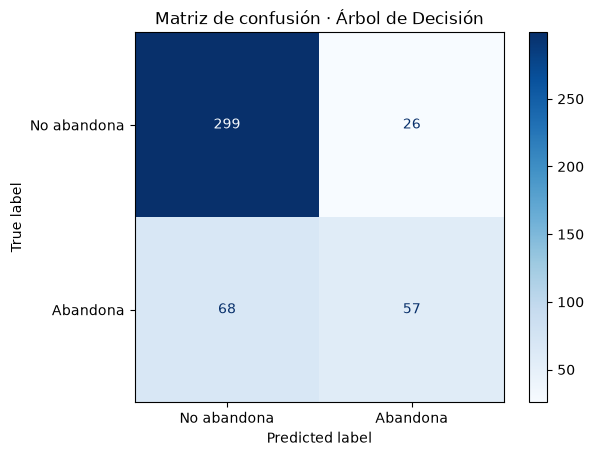

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


y_pred_arbol = arbol.predict(X_test)

# 2. Crear la visualización de la matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_arbol, 
    display_labels=["No abandona", "Abandona"], 
    cmap="Blues"
)
plt.title("Matriz de confusión · Árbol de Decisión")
plt.grid(False)
plt.show()

el árbol acierta el 79,1 % de las veces, pero esa cifra engaña porque el 72 % de los clientes no abandona.

In [ ]:

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Modelo 2a
log_base = LogisticRegression(max_iter=1000, random_state=SEED)
log_base.fit(X_train_sc, y_train)
y_pred_log_base = log_base.predict(X_test_sc)
print("=== Regresión logística SIN balanceo ===")
print(classification_report(y_test, y_pred_log_base, target_names=["No abandona", "Abandona"]))

# Modelo 2b
logistica = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
logistica.fit(X_train_sc, y_train)
y_pred_log = logistica.predict(X_test_sc)
print("=== Regresión logística CON balanceo ===")
print(classification_report(y_test, y_pred_log, target_names=["No abandona", "Abandona"]))

=== Regresión logística SIN balanceo ===
              precision    recall  f1-score   support

 No abandona       0.83      0.93      0.88       325
    Abandona       0.73      0.52      0.61       125

    accuracy                           0.81       450
   macro avg       0.78      0.72      0.74       450
weighted avg       0.81      0.81      0.80       450

=== Regresión logística CON balanceo ===
              precision    recall  f1-score   support

 No abandona       0.88      0.77      0.82       325
    Abandona       0.54      0.72      0.62       125

    accuracy                           0.75       450
   macro avg       0.71      0.74      0.72       450
weighted avg       0.78      0.75      0.76       450



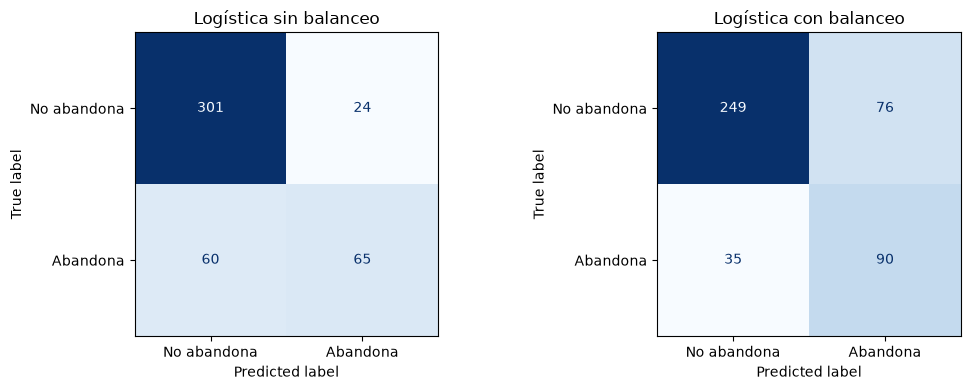

In [ ]:
# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, titulo in zip(axes, [y_pred_log_base, y_pred_log],
                            ["Logística sin balanceo", "Logística con balanceo"]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No abandona", "Abandona"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(titulo)
    ax.grid(False)
plt.tight_layout()
plt.show()


* **Sin balanceo:** accuracy 81,3 %, precision 73 % y recall 52 % (detecta 65 de 125 abandonos y deja ir a 60). 
* **Con `class_weight="balanced"`:** el recall sube a **72 %** (detecta 90 de 125 abandonos, solo se escapan 35). A cambio, la precision baja a 54 %
* El F1 también es el mejor con balanceo (0,619 vs 0,607 sin balanceo y 0,548 del árbol)

El accuracy bajó

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Crear y entrenar un árbol sin límite de profundidad (max_depth=None por defecto)
arbol_sin_limite = DecisionTreeClassifier(random_state=42)
arbol_sin_limite.fit(X_train, y_train)

# Calcular accuracy en entrenamiento y en prueba
acc_train_sin = accuracy_score(y_train, arbol_sin_limite.predict(X_train))
acc_test_sin = accuracy_score(y_test, arbol_sin_limite.predict(X_test))

print(f"Árbol sin límite -> Accuracy Train: {acc_train_sin * 100:.2f}%")
print(f"Árbol sin límite -> Accuracy Test:  {acc_test_sin * 100:.2f}%")

Árbol sin límite -> Accuracy Train: 100.00%
Árbol sin límite -> Accuracy Test:  72.89%


**Lectura:** al quitar `max_depth`, el árbol obtiene 100 % de accuracy en train pero solo 72,9 % en test. 

In [24]:
# Probar max_depth entre 3 y 6, mostrando también el recall (nuestra métrica de interés)
for depth in range(3, 7):
    arbol_temp = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    arbol_temp.fit(X_train, y_train)

    acc_train = accuracy_score(y_train, arbol_temp.predict(X_train))
    pred_te = arbol_temp.predict(X_test)
    acc_test = accuracy_score(y_test, pred_te)
    rec_test = recall_score(y_test, pred_te)

    print(f"max_depth = {depth} -> Train: {acc_train*100:.2f}% | Test: {acc_test*100:.2f}% | Recall test (abandona): {rec_test*100:.1f}%")

max_depth = 3 -> Train: 82.00% | Test: 79.11% | Recall test (abandona): 45.6%
max_depth = 4 -> Train: 84.00% | Test: 79.11% | Recall test (abandona): 46.4%
max_depth = 5 -> Train: 85.81% | Test: 79.11% | Recall test (abandona): 43.2%
max_depth = 6 -> Train: 88.29% | Test: 78.22% | Recall test (abandona): 41.6%


con `max_depth` entre 3 y 6, el accuracy en test es prácticamente igual (79,1 % para profundidades 3, 4 y 5, y baja a 78,2 % con 6) mientras que el accuracy en train sigue subiendo (82 % → 88,3 %). Es decir, después de profundidad 3-4 el árbol solo gana memoria, no capacidad de predecir; la brecha train-test crece.

In [25]:
# Tabla resumen de los modelos de clasificación (todos evaluados en test, clase "Abandona")
modelos = {
    "Árbol (max_depth=3)": y_pred_arbol,
    "Logística sin balanceo": y_pred_log_base,
    "Logística con balanceo": y_pred_log,
}
resumen_clf = pd.DataFrame({
    nombre: {
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    } for nombre, p in modelos.items()
}).T.round(3)
resumen_clf

,Accuracy,Precision,Recall,F1
Árbol (max_depth=3),0.791,0.687,0.456,0.548
Logística sin balanceo,0.813,0.730,0.520,0.607
Logística con balanceo,0.753,0.542,0.720,0.619


In [ ]:

coef_log = pd.Series(logistica.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
display(coef_log.round(2).head(8).to_frame('coef. logística (escalada)'))

# Árbol (importancias)
imp = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
display(imp.round(3).head(8).to_frame('importancia árbol'))

,coef. logística (escalada)
dias_desde_ultimo_pedido,0.71
pedidos_mes,-0.67
calificacion_app,-0.57
plan_premium_Si,-0.56
quejas_6m,0.46
ticket_promedio,0.44
antiguedad_meses,-0.29
tiempo_entrega_promedio_min,0.28


,importancia árbol
calificacion_app,0.611
dias_desde_ultimo_pedido,0.314
pedidos_mes,0.070
ticket_promedio,0.006
antiguedad_meses,0.000
edad,0.000
tiempo_entrega_promedio_min,0.000
distancia_promedio_km,0.000


### si DomiCali quiere no dejar escapar a clientes que se van, ¿qué métrica priorizas y qué modelo eliges?


priorizaría el **recall** de la clase "Abandona". Para DomiCali es mucho más costoso perder a un cliente sin haberle ofrecido nada (falso negativo) que regalar un beneficio a alguien que igual se iba a quedar (falso positivo). El modelo elegido es la **regresión logística con `class_weight="balanced"`**: detecta al 72 % de los clientes que se van (contra 52 % de la logística sin balanceo y 46 % del árbol) y tiene el mejor F1. Su costo es que cerca de la mitad de las alertas (46 %) serán falsas alarmas, por lo que el beneficio que se ofrezca debe ser barato (por ejemplo, un cupón o envío gratis) para que la campaña siga siendo rentable.

## Paso 4: Modelos de regresión (¿cuánto gastará el cliente?)

In [27]:
y = df['gasto_proximo_mes']

#dividir los datos 
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, 
    y, 
    test_size=0.3, 
    random_state=42
)

print("✅ ¡Datos divididos exitosamente!")
print(f"Registros para entrenamiento (70%): {X_train_reg.shape[0]}")
print(f"Registros para prueba (30%): {X_test_reg.shape[0]}")

✅ ¡Datos divididos exitosamente!
Registros para entrenamiento (70%): 1050
Registros para prueba (30%): 450


In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metricas(nombre, y_real, y_pred):
    # Devuelve MAE, RMSE y R² de un modelo en test
    return {"Modelo": nombre,
            "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
            "R2": r2_score(y_real, y_pred)}

# Modelo 1: Regresión lineal
lr_model = LinearRegression()
lr_model.fit(X_train_reg, y_train_reg)
y_pred_lr = lr_model.predict(X_test_reg)
print("--- MODELO: Regresión Lineal ---")
print(f"MAE:  ${mean_absolute_error(y_test_reg, y_pred_lr):,.0f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test_reg, y_pred_lr)):,.0f}")
print(f"R²:   {r2_score(y_test_reg, y_pred_lr):.4f}")

--- MODELO: Regresión Lineal ---
MAE:  $123,516
RMSE: $175,986
R²:   0.7566


In [29]:
# Modelo 2: Árbol de decisión para regresión (sin límite de profundidad)
dt_reg_model = DecisionTreeRegressor(random_state=SEED)
dt_reg_model.fit(X_train_reg, y_train_reg)
y_pred_dt = dt_reg_model.predict(X_test_reg)

print("--- MODELO: Árbol de Decisión (sin max_depth) ---")
print(f"MAE:  ${mean_absolute_error(y_test_reg, y_pred_dt):,.0f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test_reg, y_pred_dt)):,.0f}")
print(f"R² test:  {r2_score(y_test_reg, y_pred_dt):.4f}")
print(f"R² train: {r2_score(y_train_reg, dt_reg_model.predict(X_train_reg)):.4f}  <- ojo: perfecto en train")

--- MODELO: Árbol de Decisión (sin max_depth) ---
MAE:  $94,281
RMSE: $122,645
R² test:  0.8818
R² train: 1.0000  <- ojo: perfecto en train


In [30]:
# El árbol sin límite memoriza el train (R² = 1). Elegimos max_depth con validación cruzada SOLO sobre train
from sklearn.model_selection import cross_val_score

resultados_cv = []
for d in range(2, 11):
    mae_cv = -cross_val_score(DecisionTreeRegressor(max_depth=d, random_state=SEED),
                              X_train_reg, y_train_reg, cv=5,
                              scoring="neg_mean_absolute_error").mean()
    resultados_cv.append((d, mae_cv))
cv_df = pd.DataFrame(resultados_cv, columns=["max_depth", "MAE_cv"])
mejor_depth = int(cv_df.loc[cv_df["MAE_cv"].idxmin(), "max_depth"])
print(cv_df.round(0).to_string(index=False))
print("\nMejor max_depth por validación cruzada:", mejor_depth)

dt_podado = DecisionTreeRegressor(max_depth=mejor_depth, random_state=SEED)
dt_podado.fit(X_train_reg, y_train_reg)
y_pred_dt_p = dt_podado.predict(X_test_reg)

 max_depth   MAE_cv
         2 115357.0
         3  88112.0
         4  78879.0
         5  76209.0
         6  77044.0
         7  78782.0
         8  81029.0
         9  82881.0
        10  85071.0

Mejor max_depth por validación cruzada: 5


In [31]:
# Tabla comparativa de regresión (métricas en test)
resumen_reg = pd.DataFrame([
    metricas("Regresión lineal", y_test_reg, y_pred_lr),
    metricas("Árbol sin límite", y_test_reg, y_pred_dt),
    metricas(f"Árbol max_depth={mejor_depth}", y_test_reg, y_pred_dt_p),
]).set_index("Modelo")
resumen_reg.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.3f}"})

AttributeError: The '.style' accessor requires jinja2

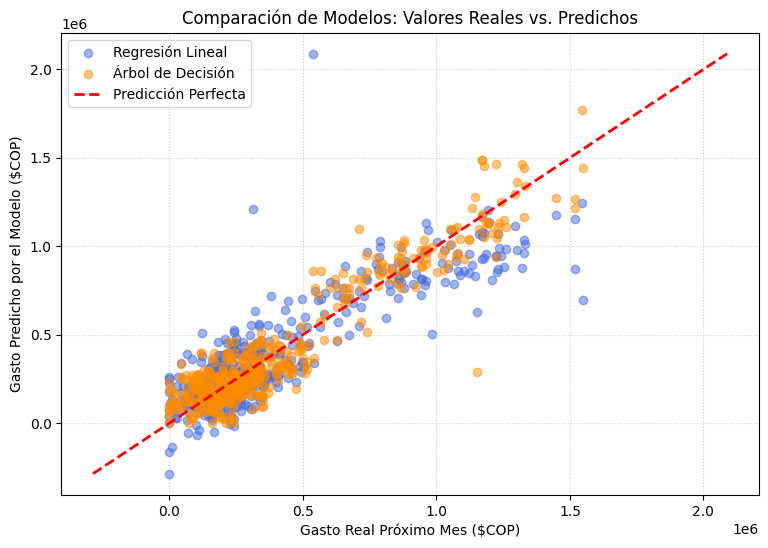

In [ ]:
plt.figure(figsize=(9, 6))

# Puntos de la Regresión Lineal
plt.scatter(y_test_reg, y_pred_lr, alpha=0.5, color='royalblue', label='Regresión Lineal')

# Puntos del Árbol de Decisión
plt.scatter(y_test_reg, y_pred_dt_p, alpha=0.5, color='darkorange', label=f'Árbol (max_depth={mejor_depth})')

# Línea de predicción perfecta (ideal)
val_min = min(y_test_reg.min(), y_pred_lr.min(), y_pred_dt_p.min())
val_max = max(y_test_reg.max(), y_pred_lr.max(), y_pred_dt_p.max())
plt.plot([val_min, val_max], [val_min, val_max], 'r--', lw=2, label='Predicción Perfecta')

plt.xlabel("Gasto Real Próximo Mes ($COP)")
plt.ylabel("Gasto Predicho por el Modelo ($COP)")
plt.title("Comparación de Modelos: Valores Reales vs. Predichos")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

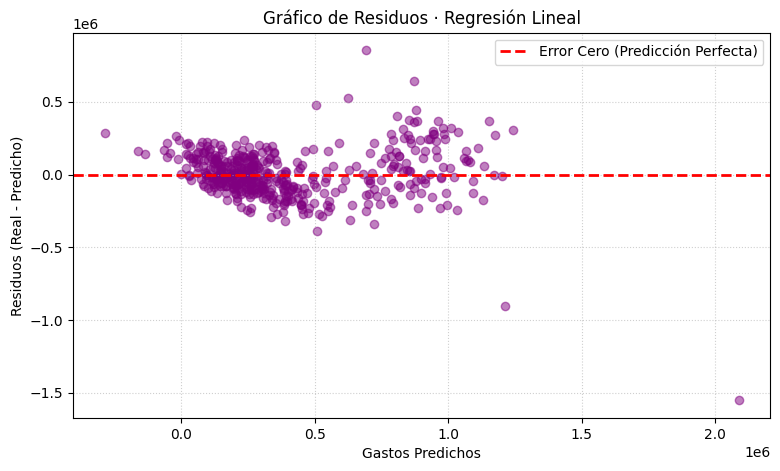

In [ ]:
plt.figure(figsize=(9, 5))

# Calcular residuos
residuos_lr = y_test_reg - y_pred_lr

# Gráfico de dispersión de los residuos
plt.scatter(y_pred_lr, residuos_lr, alpha=0.5, color='purple')
plt.axhline(y=0, color='red', linestyle='--', lw=2, label='Error Cero (Predicción Perfecta)')

plt.xlabel("Gastos Predichos")
plt.ylabel("Residuos (Real - Predicho)")
plt.title("Gráfico de Residuos · Regresión Lineal")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

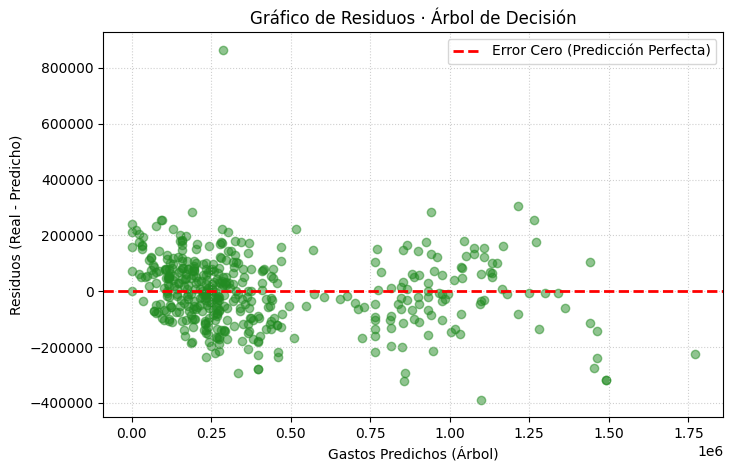

In [ ]:
plt.figure(figsize=(8, 5))

# Calcular residuos para el árbol de decisión
residuos_dt = y_test_reg - y_pred_dt_p

# Gráfico de dispersión de los residuos
plt.scatter(y_pred_dt_p, residuos_dt, alpha=0.5, color='forestgreen')
plt.axhline(y=0, color='red', linestyle='--', lw=2, label='Error Cero (Predicción Perfecta)')

plt.xlabel("Gastos Predichos (Árbol podado)")
plt.ylabel("Residuos (Real - Predicho)")
plt.title("Gráfico de Residuos · Árbol de Decisión")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

El Árbol de Decisión Regresor tuvo el mejor desempeño global, con un menor error medio ($94.280 COP) y un mayor $R^2$, mostrando un margen de desviación promedio de esa misma cifra frente al gasto real.A nivel gráfico, aunque ambos modelos muestran una tendencia lineal similar y la Regresión Lineal agrupa algunos residuos más cerca de cero, el Árbol de Decisión es notablemente más robusto ante datos atípicos y controla mejor la variabilidad general.

**Interpretación del MAE en pesos:**
* **Regresión lineal:** en promedio, el modelo se equivoca por **$123.516** al estimar el gasto del próximo mes (≈ 31 % del gasto promedio de $398.278). R² = 0,757.
* **Árbol sin límite:** se equivoca por **$94.281** (≈ 24 %), R² = 0,882. Pero ojo: tiene R² = 1,0 en train, así que está sobreajustado.
* **Árbol con `max_depth=5`** (elegido por validación cruzada solo con train): se equivoca por **$83.626** (≈ 21 %), RMSE $114.852 y R² = **0,896**. Es el mejor de los tres y el más confiable porque no memoriza.

Intercepto: -4618


,coeficiente (COP)
plan_premium_Si,139818.6
calificacion_app,88381.4
quejas_6m,-32929.0
pedidos_mes,29198.2
zona_Sur,-26077.4
zona_Oeste,-24419.6
zona_Oriente,-24012.8
zona_Norte,-18910.4
metodo_pago_Tarjeta,9279.5
antiguedad_meses,5280.6


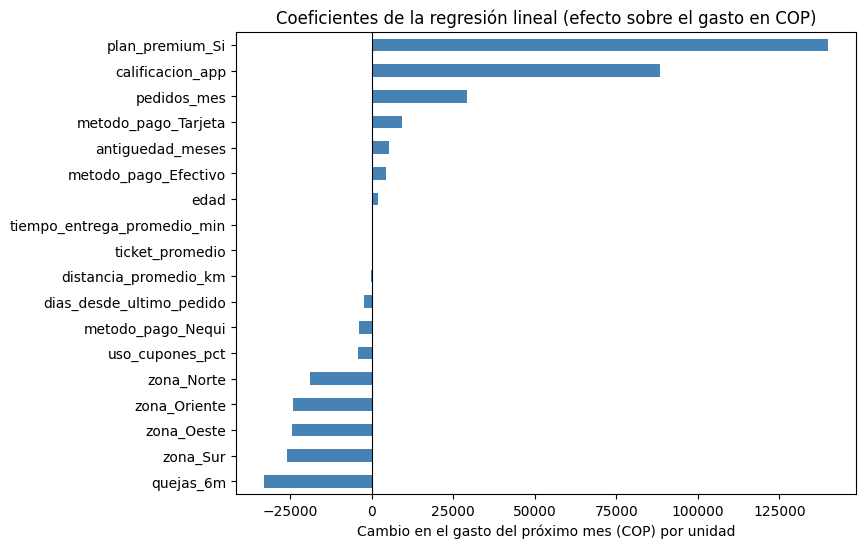

In [ ]:
# Coeficientes de la regresión lineal (en las unidades originales de cada variable)
coef = pd.Series(lr_model.coef_, index=X_train_reg.columns).sort_values(key=abs, ascending=False)
print("Intercepto:", round(lr_model.intercept_))
display(coef.round(1).to_frame("coeficiente (COP)"))

plt.figure(figsize=(8, 6))
coef.sort_values().plot(kind="barh", color="steelblue")
plt.axvline(0, color="k", lw=0.8)
plt.title("Coeficientes de la regresión lineal (efecto sobre el gasto en COP)")
plt.xlabel("Cambio en el gasto del próximo mes (COP) por unidad")
plt.show()

**Los dos coeficientes más grandes (regresión lineal):**
1. **`plan_premium_Si` = +$139.819:** manteniendo todo lo demás igual, un cliente con plan premium gasta en promedio ≈ $140.000 más al mes que uno sin plan.
2. **`calificacion_app` = +$88.381:** por cada punto adicional en la calificación de la app, el gasto esperado sube ≈ $88.000. Los clientes más satisfechos gastan más.

Otros efectos relevantes: cada queja en 6 meses reduce el gasto esperado en ≈ $33.000 y cada pedido mensual adicional lo aumenta en ≈ $29.000. Las zonas aparecen con coeficientes negativos porque se comparan contra la zona de referencia (Centro, eliminada por `drop_first=True`).

**Advertencias:** (1) los coeficientes están en las unidades de cada variable, así que no se pueden comparar directamente (el de `ticket_promedio` parece diminuto porque está medido por cada peso); (2) son asociaciones, no causalidad: no podemos afirmar que dar plan premium *cause* un mayor gasto; (3) el signo negativo de `ticket_promedio` es contraintuitivo y probablemente se deba a su relación con `pedidos_mes` y a la no linealidad, otra señal de que la regresión lineal no es el mejor modelo aquí.

In [ ]:
# ¿Los errores por cliente se compensan al proyectar el ingreso total del mes? (test)
total_real = y_test_reg.sum()
filas=[]
for nombre,pred in [('Regresión lineal',y_pred_lr),('Árbol sin límite',y_pred_dt),(f'Árbol max_depth={mejor_depth}',y_pred_dt_p)]:
    filas.append({'Modelo':nombre,'Total predicho':pred.sum(),'Total real':total_real,'Error %':(pred.sum()-total_real)/total_real*100})
pd.DataFrame(filas).set_index('Modelo').style.format({'Total predicho':'${:,.0f}','Total real':'${:,.0f}','Error %':'{:.1f}%'})

## Paso 5 (reto): Anomalías y segmentación

### 5.1 Anomalías: regla 1,5·IQR vs. IsolationForest

In [ ]:
from sklearn.ensemble import IsolationForest

df_orig = pd.read_csv("clientes_domicilios_cali.csv")   # versión original para poder ver el id_cliente
vars_anom = ['pedidos_mes', 'ticket_promedio', 'distancia_promedio_km']
df_orig['distancia_promedio_km'] = df_orig['distancia_promedio_km'].fillna(df_orig['distancia_promedio_km'].median())

# --- Regla 1,5·IQR por variable ---
flags_iqr = pd.DataFrame(index=df_orig.index)
filas = []
for v in vars_anom:
    q1, q3 = df_orig[v].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
    flags_iqr[v] = (df_orig[v] < lim_inf) | (df_orig[v] > lim_sup)
    filas.append({"variable": v, "límite inf": round(lim_inf, 1), "límite sup": round(lim_sup, 1), "atípicos": int(flags_iqr[v].sum())})
display(pd.DataFrame(filas))
df_orig['atipico_iqr'] = flags_iqr.any(axis=1)

# --- IsolationForest (2% de contaminación) sobre las mismas 3 variables ---
iso = IsolationForest(contamination=0.02, random_state=SEED)
df_orig['atipico_iso'] = iso.fit_predict(df_orig[vars_anom]) == -1

print("Atípicos por IQR (en al menos una variable):", df_orig['atipico_iqr'].sum())
print("Atípicos por IsolationForest:", df_orig['atipico_iso'].sum())
print("\n¿Coinciden?")
display(pd.crosstab(df_orig['atipico_iqr'], df_orig['atipico_iso'], rownames=['IQR'], colnames=['IsolationForest']))

,variable,límite inf,límite sup,atípicos
0,pedidos_mes,-9.0,23.0,15
1,ticket_promedio,312.5,88812.5,14
2,distancia_promedio_km,-1.1,9.3,16


Atípicos por IQR (en al menos una variable): 32
Atípicos por IsolationForest: 30

¿Coinciden?


IsolationForest,False,True
IQR,,
False,1460,8
True,10,22


In [ ]:
# Tres casos sospechosos (marcados por ambos métodos)
casos = df_orig[df_orig['atipico_iqr'] & df_orig['atipico_iso']]
casos.loc[df_orig['id_cliente'].isin(['CL01117', 'CL00074', 'CL00205']),
          ['id_cliente','antiguedad_meses','pedidos_mes','ticket_promedio','distancia_promedio_km',
           'tiempo_entrega_promedio_min','gasto_proximo_mes']]

,id_cliente,antiguedad_meses,pedidos_mes,ticket_promedio,distancia_promedio_km,tiempo_entrega_promedio_min,gasto_proximo_mes
73,CL00074,19,1,67100,59.6,6,109600
204,CL00205,4,86,433000,7.2,42,77600
1116,CL01117,33,105,379000,1.9,26,537400


In [ ]:
# Contraste: clientes que SOLO detecta IsolationForest (no el IQR univariado)
solo_iso = df_orig[df_orig['atipico_iso'] & ~df_orig['atipico_iqr']]
print(len(solo_iso), "clientes")
solo_iso[['id_cliente','plan_premium','pedidos_mes','ticket_promedio','gasto_proximo_mes']].head(5)

8 clientes


,id_cliente,plan_premium,pedidos_mes,ticket_promedio,gasto_proximo_mes
115,CL00116,Si,20,63900,1192400
134,CL00135,No,23,75700,1511900
231,CL00232,Si,23,68300,1446000
432,CL00433,No,20,82100,1547800
468,CL00469,Si,17,85400,1242800


In [ ]:
# Perfil completo de los clientes que solo marca IsolationForest
solo_iso[['antiguedad_meses','pedidos_mes','ticket_promedio','gasto_proximo_mes']].describe().round(0)

**¿Coinciden los métodos?** En buena parte sí, pero no del todo: el IQR marcó 32 clientes y el IsolationForest 30; **22 son marcados por ambos**, 10 solo por el IQR y 8 solo por el IsolationForest. La razón es que el IQR mira cada variable por separado, mientras que el IsolationForest evalúa combinaciones de las tres variables.

**Tres casos sospechosos (marcados por ambos métodos):**
1. **CL01117:** 105 pedidos al mes con ticket de $379.000 implicaría ≈ $39,8 millones mensuales, pero su gasto real del mes siguiente fue de solo $537.400. Los datos son incoherentes: probable error de captura o actividad automatizada (bot).
2. **CL00074:** distancia promedio de 59,6 km con entrega en 6 minutos (≈ 600 km/h): imposible. Es probablemente un error de captura de distancia o de tiempo. Hay otros 5 clientes con el mismo patrón, lo que sugiere una falla sistemática en el registro.
3. **CL00205:** cuenta de solo 4 meses con 86 pedidos al mes y ticket de $433.000, pero gasto del mes siguiente de $77.600. Una cuenta nueva con un volumen irreal es el perfil típico de posible fraude (por ejemplo, abuso de cupones o pagos no legítimos).

**Ojo con los falsos positivos:** los 8 clientes que solo detecta el IsolationForest son clientes con 17 a 23 pedidos al mes y gasto de $1,2 a $1,5 millones; en su mayoría llevan 38 a 54 meses en la app. Parecen **clientes VIP legítimos**, no fraude. Que un dato sea atípico no significa que sea fraudulento: el equipo de riesgo debe revisar cada caso antes de actuar.

### 5.2 Clustering con K-means

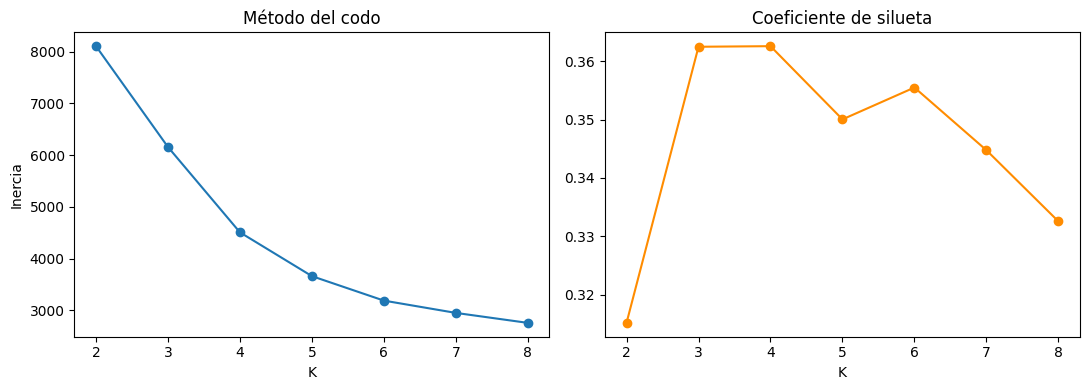

 K  inercia  silueta
 2   8108.0    0.315
 3   6157.0    0.362
 4   4506.0    0.363
 5   3659.0    0.350
 6   3186.0    0.356
 7   2948.0    0.345
 8   2755.0    0.333


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Variables de comportamiento (las de la guía) y escalado: K-means usa distancias, así que escalar es obligatorio
vars_comp = ['pedidos_mes', 'ticket_promedio', 'uso_cupones_pct', 'calificacion_app',
             'quejas_6m', 'dias_desde_ultimo_pedido', 'antiguedad_meses']
Z = StandardScaler().fit_transform(df[vars_comp])

# Método del codo (inercia) y, de apoyo, el coeficiente de silueta
ks = range(2, 9)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inercias, "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inercia")
ax[1].plot(list(ks), siluetas, "o-", color="darkorange"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("K")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"K": list(ks), "inercia": np.round(inercias), "silueta": np.round(siluetas, 3)}).to_string(index=False))

la inercia baja rápido hasta K = 3 o 4 y luego se aplana (el "codo"). La silueta es máxima en K = 3 (0,362) y K = 4 (0,363), casi un empate. Elijo **K = 4**: con K = 3, las 12 cuentas atípicas quedan mezcladas con los clientes leales y distorsionan su perfil; con K = 4 se separan en su propio grupo, que coincide con las anomalías detectadas antes.

In [ ]:
# K-means con K = 4
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
df['cluster'] = km.labels_

# Perfil promedio por cluster (incluye variables que NO se usaron para agrupar, solo para describir)
perfil = df.groupby('cluster')[vars_comp + ['plan_premium_Si', 'gasto_proximo_mes', 'abandono']].mean()
perfil['n_clientes'] = df['cluster'].value_counts()
display(perfil.round(2))

# Nombres de negocio asignados por reglas sobre el perfil (así no dependen del número que K-means le ponga a cada cluster)
nombres = {}
nombres[perfil['pedidos_mes'].idxmax()] = "Cuentas atípicas (posible fraude/error)"
resto = perfil.drop(index=list(nombres))
nombres[resto['quejas_6m'].idxmax()] = "En riesgo / insatisfechos"
resto = resto.drop(index=[c for c in nombres if c in resto.index])
nombres[resto['pedidos_mes'].idxmax()] = "Frecuentes leales de alto valor"
resto = resto.drop(index=[c for c in nombres if c in resto.index])
nombres[resto.index[0]] = "Ocasionales cazadores de cupones"
df['segmento'] = df['cluster'].map(nombres)
print(nombres)
df['segmento'].value_counts()

,pedidos_mes,ticket_promedio,uso_cupones_pct,calificacion_app,quejas_6m,dias_desde_ultimo_pedido,antiguedad_meses,plan_premium_Si,gasto_proximo_mes,abandono,n_clientes
cluster,,,,,,,,,,,
0,5.71,35852.51,47.95,4.15,0.68,13.22,12.58,0.11,257929.12,0.24,838
1,14.26,67586.57,9.79,4.55,0.30,3.90,37.22,0.73,932189.71,0.03,350
2,71.33,383833.33,65.32,4.26,1.00,10.50,16.33,0.08,480350.00,0.17,12
3,3.94,45177.33,19.19,2.82,3.08,29.46,23.59,0.21,164141.00,0.69,300


{np.int32(2): 'Cuentas atípicas (posible fraude/error)', np.int32(3): 'En riesgo / insatisfechos', np.int32(1): 'Frecuentes leales de alto valor', np.int32(0): 'Ocasionales cazadores de cupones'}


segmento
Ocasionales cazadores de cupones           838
Frecuentes leales de alto valor            350
En riesgo / insatisfechos                  300
Cuentas atípicas (posible fraude/error)     12
Name: count, dtype: int64

In [ ]:
# ¿El cluster de cuentas atípicas coincide con las anomalías del punto 5.1?
display(pd.crosstab(df['segmento'], df_orig['atipico_iso'], rownames=['segmento'], colnames=['IsolationForest']))
display(pd.crosstab(df['segmento'], df_orig['atipico_iqr'], rownames=['segmento'], colnames=['IQR']))

# ¿Qué pasa con K = 3? (para sustentar la elección de K)
km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Z)
perfil3 = df.assign(c3=km3.labels_).groupby('c3')[vars_comp].mean()
perfil3['n_clientes'] = pd.Series(km3.labels_).value_counts()
perfil3.round(2)

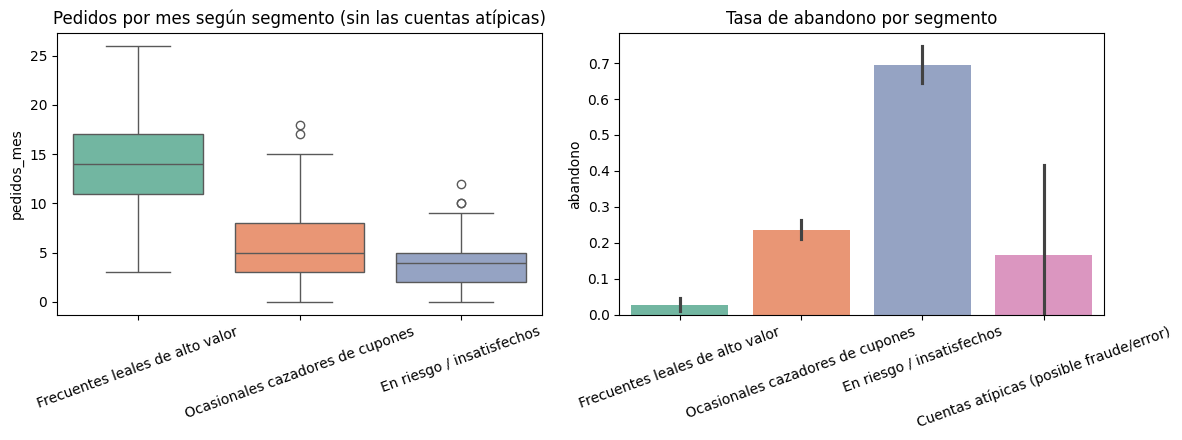

In [ ]:
# Visualización rápida de los segmentos
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df[df['pedidos_mes'] < 40], x='segmento', y='pedidos_mes', ax=ax[0], palette='Set2')
ax[0].set_title('Pedidos por mes según segmento (sin las cuentas atípicas)'); ax[0].set_xlabel(''); ax[0].tick_params(axis='x', rotation=20)
sns.barplot(data=df, x='segmento', y='abandono', ax=ax[1], palette='Set2')
ax[1].set_title('Tasa de abandono por segmento'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Perfiles de negocio (promedios por cluster):**
* **Frecuentes leales de alto valor (350 clientes):** ≈ 14 pedidos al mes, ticket de $67.600, 73 % con plan premium, casi 37 meses de antigüedad, calificación de 4,55, muy pocas quejas y poco uso de cupones. Gastan ≈ **$932.000** el mes siguiente y solo el 3 % abandona. Son el corazón del negocio.
* **Ocasionales cazadores de cupones (838 clientes):** ≈ 5,7 pedidos al mes, ticket de $35.900, usan cupón en el 48 % de sus pedidos, ≈ 13 meses de antigüedad. Gastan ≈ $258.000 y el 24 % abandona. Compran cuando hay descuento.
* **En riesgo / insatisfechos (300 clientes):** calificación de 2,8, 3,1 quejas en 6 meses, casi 30 días sin pedir. **69 % abandona** y gastan solo ≈ $164.000. Es el segmento donde se pierde el dinero.
* **Cuentas atípicas (12 clientes):** ≈ 71 pedidos al mes con ticket de $384.000: coinciden con las anomalías del punto 5.1 y deben ser auditadas por riesgo.

**Acciones sugeridas:** fidelizar a los leales (beneficios exclusivos, soporte prioritario); empujar a los ocasionales hacia el plan premium con una prueba gratuita; resolver quejas de los insatisfechos y ofrecerles un beneficio de retención; y auditar las cuentas atípicas.

## Paso 6: Conclusiones para la gerencia

¿Quién se va a ir? Regresión logística balanceada.
Pilla a 7 de cada 10 clientes que abandonan (72%), mejor que la otra versión (50%) y que el árbol. Sirve para saber a quién llamar, pero no es exacta: de 100 que marca en riesgo, 54 sí se iban y 46 se quedaban igual. La idea es darles algo barato como envío gratis o cupón y comparar con los que no reciben nada.

¿Cuánto van a gastar? Árbol de decisión (profundidad 5).
Le pifia por $84.000 promedio por cliente (21% del gasto medio de $398.000) y le pega al 90% de los cambios de gasto. La regresión lineal le pifia por $124.000 y solo le pega al 76%. Sirve bastante para calcular la plata del mes porque los errores se van compensando. Toca usarlo para el presupuesto y actualizarlo cada mes.

Lo que mueve el negocio.
Los que tienen plan premium y califican bien la app gastan mucho más. Las quejas y no pedir en días son la señal fija de que se van a ir. Hay que meterle a la suscripción premium y solucionar rápido las quejas.

Segmentos.
Hay 4 tipos de clientes: leales (350, gastan ~$932.000 y casi no se van), cazadores de cupones (838), en riesgo (300, el 69% se va) y casos raros (12). Hay que enfocar las ganas en los de riesgo, consentir a los leales y revisar las 12 cuentas raras con la gente de auditoría, porque hay datos locos como 59 km en 6 minutos.

## Declaración de uso de IA generativa (Nivel 3)

Usé un asistente de IA generativa (Claude) para apoyarme en el código del notebook, anomalías y clustering, y para corregir errores de orden de ejecución. También me apoyó en la redacción de varias interpretaciones y de las conclusiones